# Data Horizon — Inteligencia Territorial
## Revisión y mejora del análisis de datos (V2)

Este notebook integra registros georreferenciados de delitos de CABA correspondientes a 2024 con información de luminosidad nocturna satelital NASA VIIRS Black Marble.

### Objetivos de esta versión
- Auditar y documentar el procesamiento de punta a punta.
- Unificar criterios espaciales y temporales.
- Revisar calidad y tratamiento de las observaciones satelitales.
- Verificar correlaciones mensuales y espaciales.
- Analizar outliers, distribuciones y posibles relaciones no lineales.
- Construir una grilla territorial que incluya celdas con cero delitos nocturnos.
- Revisar la clasificación Bajo / Medio / Alto como categorías **relativas**.
- Generar perfiles territoriales e indicadores para el dashboard.
- Evaluar K-Means solo si las variables disponibles lo justifican.
- Exportar tablas reutilizables para el producto.

> **Importante:** este análisis estudia asociaciones. No se interpretan correlaciones como causalidad y los grupos/categorías territoriales no representan niveles absolutos de seguridad.

## 0. Preparación del entorno

La celda siguiente intenta cargar `delitos_2024.csv` desde `/content`.  
Si el archivo no está disponible —por ejemplo, al abrir el Colab desde otra computadora— permite subirlo manualmente.

In [ ]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ARCHIVO_DELITOS = "/content/delitos_2024.csv"

if not Path(ARCHIVO_DELITOS).exists():
    try:
        from google.colab import files
        print("No se encontró delitos_2024.csv en /content.")
        print("Seleccioná el archivo desde tu computadora.")
        subidos = files.upload()
        if "delitos_2024.csv" not in subidos:
            nombre_subido = next(iter(subidos))
            os.rename(f"/content/{nombre_subido}", ARCHIVO_DELITOS)
    except Exception as e:
        raise FileNotFoundError(
            "No se encontró delitos_2024.csv. Subilo manualmente al entorno de Colab."
        ) from e

print("Archivo disponible:", ARCHIVO_DELITOS)

Archivo disponible: /content/delitos_2024.csv


## 1. Carga y auditoría inicial

Se conserva una copia `df_raw` sin modificar y se trabaja sobre `df`.  
Esto permite documentar con claridad qué registros se excluyen y por qué.

In [ ]:
# Parámetros generales
ANIO_ANALISIS = 2024

# Área rectangular usada también para NASA Black Marble.
# Es una aproximación del área de estudio, no un límite administrativo exacto de CABA.
LAT_MIN = -34.7050
LAT_MAX = -34.5265
LON_MIN = -58.5315
LON_MAX = -58.3350

df_raw = pd.read_csv(ARCHIVO_DELITOS)
df = df_raw.copy()

print("=== CARGA ===")
print(f"Filas originales: {len(df_raw):,}")
print(f"Columnas: {df_raw.shape[1]}")
print(df_raw.columns.tolist())

# Conversiones controladas
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")

for col in ["anio", "franja", "comuna", "latitud", "longitud", "cantidad"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("\n=== TIPOS DE DATOS ===")
print(df.dtypes)

print("\n=== NULOS ===")
nulos = df.isna().sum().to_frame("nulos")
nulos["porcentaje"] = (nulos["nulos"] / len(df) * 100).round(2)
display(nulos)

print("\n=== DUPLICADOS ===")
print("Filas completamente duplicadas:", df.duplicated().sum())

print("\n=== FECHAS ===")
print("Fecha mínima:", df["fecha"].min())
print("Fecha máxima:", df["fecha"].max())
print("Fechas no interpretables:", df["fecha"].isna().sum())

inconsistencia_anio = (
    df["fecha"].notna()
    & df["anio"].notna()
    & (df["fecha"].dt.year != df["anio"])
)
print("Inconsistencias anio vs fecha:", inconsistencia_anio.sum())

print("\n=== FRANJA HORARIA ===")
franja_valida = df["franja"].between(0, 23)
print("Franjas válidas 0-23:", franja_valida.sum())
print("Franjas nulas:", df["franja"].isna().sum())
print("Franjas fuera de 0-23:", (df["franja"].notna() & ~franja_valida).sum())

print("\n=== COORDENADAS ===")
coord_presentes = df["latitud"].notna() & df["longitud"].notna()
coord_mundo_valida = (
    df["latitud"].between(-90, 90)
    & df["longitud"].between(-180, 180)
)
coord_area_estudio = (
    df["latitud"].between(LAT_MIN, LAT_MAX)
    & df["longitud"].between(LON_MIN, LON_MAX)
)

print("Con ambas coordenadas:", coord_presentes.sum())
print("Coordenadas válidas globalmente:", coord_mundo_valida.sum())
print("Dentro del área rectangular de estudio:", coord_area_estudio.sum())
print("Sin coordenadas completas:", (~coord_presentes).sum())
print(
    "Coordenadas válidas pero fuera del área:",
    (coord_presentes & coord_mundo_valida & ~coord_area_estudio).sum()
)

display(
    df.loc[
        ~coord_area_estudio,
        ["id-mapa", "barrio", "comuna", "latitud", "longitud"]
    ].head(15)
)

=== CARGA ===
Filas originales: 158,838
Columnas: 15
['id-mapa', 'anio', 'mes', 'dia', 'fecha', 'franja', 'tipo', 'subtipo', 'uso_arma', 'uso_moto', 'barrio', 'comuna', 'latitud', 'longitud', 'cantidad']

=== TIPOS DE DATOS ===
id-mapa              int64
anio                 int64
mes                 object
dia                 object
fecha       datetime64[ns]
franja             float64
tipo                object
subtipo             object
uso_arma            object
uso_moto            object
barrio              object
comuna             float64
latitud            float64
longitud           float64
cantidad             int64
dtype: object

=== NULOS ===


,nulos,porcentaje
id-mapa,0,0.0000
anio,0,0.0000
mes,0,0.0000
dia,0,0.0000
fecha,0,0.0000
franja,47,0.0300
tipo,0,0.0000
subtipo,0,0.0000
uso_arma,0,0.0000
uso_moto,0,0.0000



=== DUPLICADOS ===
Filas completamente duplicadas: 0

=== FECHAS ===
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2024-12-31 00:00:00
Fechas no interpretables: 0
Inconsistencias anio vs fecha: 0

=== FRANJA HORARIA ===
Franjas válidas 0-23: 158791
Franjas nulas: 47
Franjas fuera de 0-23: 0

=== COORDENADAS ===
Con ambas coordenadas: 155004
Coordenadas válidas globalmente: 154998
Dentro del área rectangular de estudio: 154916
Sin coordenadas completas: 3834
Coordenadas válidas pero fuera del área: 82


,id-mapa,barrio,comuna,latitud,longitud
889,1400501,NaN,NaN,NaN,NaN
1757,1401369,NaN,NaN,NaN,NaN
1781,1401393,NaN,NaN,NaN,NaN
2895,1402507,NaN,NaN,NaN,NaN
5173,1404785,NaN,NaN,NaN,NaN
5487,1405099,NaN,NaN,NaN,NaN
7337,1406949,NaN,NaN,NaN,NaN
8222,1407834,NaN,NaN,NaN,NaN
9452,1409064,NaN,NaN,NaN,NaN
11886,1411498,NaN,NaN,NaN,NaN


## 2. Construcción del dataset base consistente

Criterios:
- fecha válida de 2024;
- franja horaria entre 0 y 23;
- coordenadas dentro de la misma área rectangular usada en Earth Engine.

Este mismo `df_base` se usa en las etapas posteriores.

In [ ]:
criterio_base = (
    df["fecha"].notna()
    & df["fecha"].dt.year.eq(ANIO_ANALISIS)
    & df["franja"].between(0, 23)
    & df["latitud"].between(LAT_MIN, LAT_MAX)
    & df["longitud"].between(LON_MIN, LON_MAX)
)

df_base = df.loc[criterio_base].copy()

df_base["mes_num"] = df_base["fecha"].dt.month
df_base["dia_semana_num"] = df_base["fecha"].dt.dayofweek
df_base["es_fin_de_semana"] = df_base["dia_semana_num"].isin([5, 6]).astype(int)

print("=== RESULTADO DEL FILTRO BASE ===")
print(f"Registros originales: {len(df_raw):,}")
print(f"Registros válidos: {len(df_base):,}")
print(f"Registros excluidos: {len(df_raw)-len(df_base):,}")
print(f"Porcentaje conservado: {len(df_base)/len(df_raw)*100:.2f}%")
print("Rango final:", df_base["fecha"].min(), "a", df_base["fecha"].max())

display(df_base.head())

=== RESULTADO DEL FILTRO BASE ===
Registros originales: 158,838
Registros válidos: 154,875
Registros excluidos: 3,963
Porcentaje conservado: 97.51%
Rango final: 2024-01-01 00:00:00 a 2024-12-31 00:00:00


,id-mapa,anio,mes,dia,fecha,franja,tipo,subtipo,uso_arma,uso_moto,barrio,comuna,latitud,longitud,cantidad,mes_num,dia_semana_num,es_fin_de_semana
0,1399612,2024,ENERO,LUNES,2024-01-01,17.0000,Robo,Robo total,SI,NO,CHACARITA,15.0000,-34.5852,-58.4540,1,1,0,0
1,1399613,2024,ENERO,LUNES,2024-01-01,6.0000,Robo,Robo total,SI,NO,CHACARITA,15.0000,-34.5842,-58.4535,1,1,0,0
2,1399614,2024,ENERO,LUNES,2024-01-01,1.0000,Hurto,Hurto total,NO,NO,MATADEROS,9.0000,-34.6644,-58.5021,1,1,0,0
3,1399615,2024,ENERO,LUNES,2024-01-01,19.0000,Robo,Robo total,NO,NO,PALERMO,14.0000,-34.5649,-58.4349,1,1,0,0
4,1399616,2024,ENERO,LUNES,2024-01-01,20.0000,Hurto,Hurto total,NO,NO,SAN NICOLAS,1.0000,-34.6055,-58.3912,1,1,0,0


## 3. EDA general de delitos 2024

Los conteos son **registros observados**, no tasas ajustadas por población, circulación de personas u otras exposiciones.  
Por lo tanto, no deben interpretarse directamente como “peligrosidad”.

=== TIPOS DE DELITO ===


,cantidad
tipo,
Robo,68304
Hurto,62655
Vialidad,9556
Lesiones,7606
Amenazas,6676
Homicidios,78


=== SUBTIPOS ===


,cantidad
subtipo,
Robo total,67165
Hurto total,58005
Lesiones por siniestros viales,9446
Lesiones Dolosas,7606
Amenazas,6676
Hurto automotor,4650
Robo automotor,1139
Muertes por siniestros viales,110
Homicidios dolosos,78


=== COMUNAS ===


,cantidad
comuna,
1.0000,20816
2.0000,6689
3.0000,12531
4.0000,14238
5.0000,8026
6.0000,6860
7.0000,12495
8.0000,10006
9.0000,8423


=== TOP 15 BARRIOS ===


,cantidad
barrio,
PALERMO,12789
BALVANERA,9966
FLORES,8508
CABALLITO,6860
RECOLETA,6689
ALMAGRO,6026
VILLA LUGANO,5860
SAN NICOLAS,5831
BARRACAS,5389


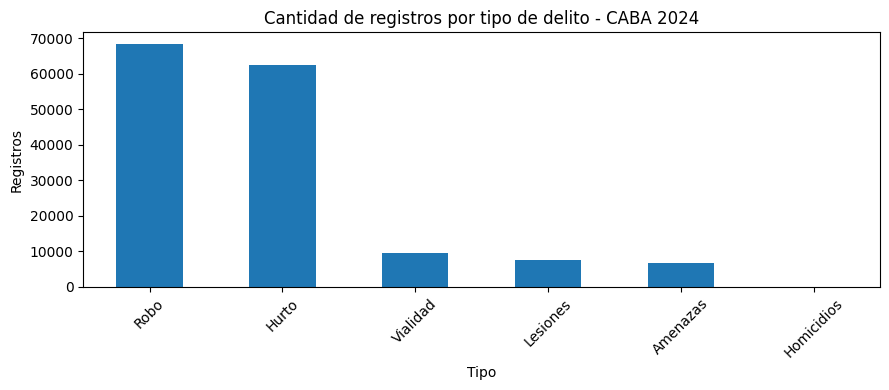

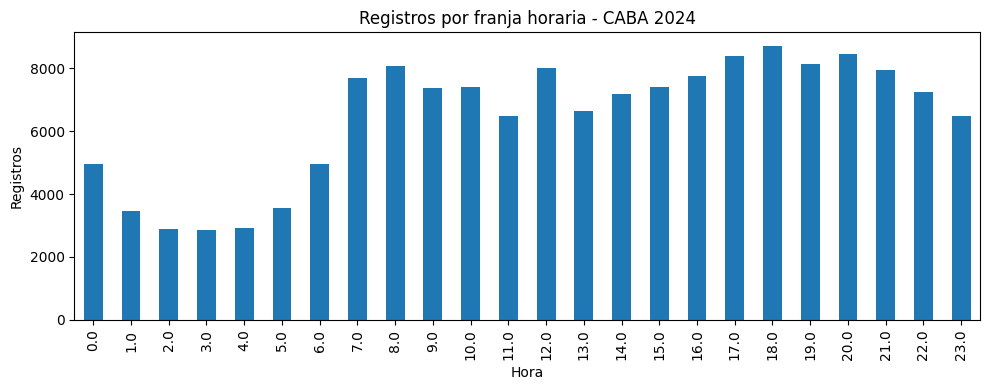

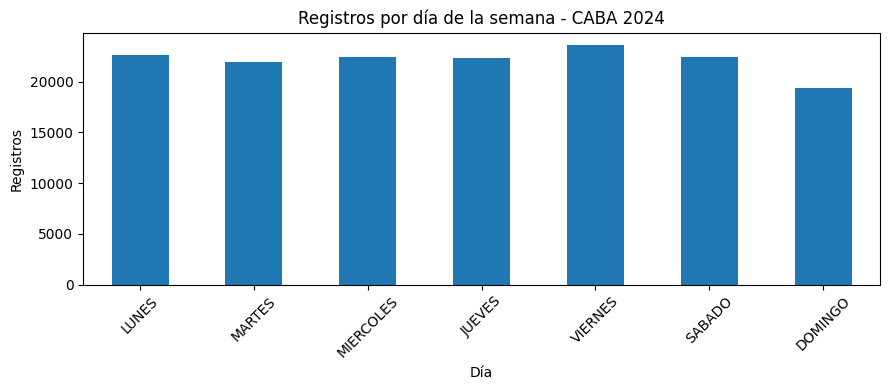

In [ ]:
print("=== TIPOS DE DELITO ===")
display(df_base["tipo"].value_counts().rename("cantidad").to_frame())

print("=== SUBTIPOS ===")
display(df_base["subtipo"].value_counts().rename("cantidad").to_frame())

print("=== COMUNAS ===")
display(df_base["comuna"].value_counts().sort_index().rename("cantidad").to_frame())

print("=== TOP 15 BARRIOS ===")
display(df_base["barrio"].value_counts().head(15).rename("cantidad").to_frame())

fig = plt.figure(figsize=(9, 4))
df_base["tipo"].value_counts().plot(kind="bar")
plt.title("Cantidad de registros por tipo de delito - CABA 2024")
plt.xlabel("Tipo")
plt.ylabel("Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(10, 4))
df_base["franja"].value_counts().sort_index().plot(kind="bar")
plt.title("Registros por franja horaria - CABA 2024")
plt.xlabel("Hora")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

orden_dias = ["LUNES", "MARTES", "MIERCOLES", "JUEVES", "VIERNES", "SABADO", "DOMINGO"]
fig = plt.figure(figsize=(9, 4))
df_base["dia"].value_counts().reindex(orden_dias).plot(kind="bar")
plt.title("Registros por día de la semana - CABA 2024")
plt.xlabel("Día")
plt.ylabel("Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Definición y auditoría del período nocturno

Se conserva la definición preliminar utilizada en la primera versión: **20:00 a 06:59**.  
La definición se deja explícita para que pueda modificarse y reproducirse fácilmente.

In [ ]:
HORA_NOCHE_INICIO = 20
HORA_NOCHE_FIN = 6

es_nocturno = (
    (df_base["franja"] >= HORA_NOCHE_INICIO)
    | (df_base["franja"] <= HORA_NOCHE_FIN)
)

df_nocturno = df_base.loc[es_nocturno].copy()

print("Registros base:", len(df_base))
print("Registros nocturnos:", len(df_nocturno))
print(f"Porcentaje nocturno: {len(df_nocturno)/len(df_base)*100:.2f}%")

print("\nPor hora nocturna:")
display(
    df_nocturno["franja"]
    .value_counts()
    .sort_index()
    .rename("cantidad")
    .to_frame()
)

print("\nPor tipo:")
display(df_nocturno["tipo"].value_counts().rename("cantidad").to_frame())

print("\nPor comuna:")
display(df_nocturno["comuna"].value_counts().sort_index().rename("cantidad").to_frame())

Registros base: 154875
Registros nocturnos: 55672
Porcentaje nocturno: 35.95%

Por hora nocturna:


,cantidad
franja,
0.0000,4943
1.0000,3469
2.0000,2887
3.0000,2842
4.0000,2923
5.0000,3555
6.0000,4943
20.0000,8448
21.0000,7949



Por tipo:


,cantidad
tipo,
Robo,28555
Hurto,19689
Lesiones,3037
Vialidad,2297
Amenazas,2048
Homicidios,46



Por comuna:


,cantidad
comuna,
1.0000,7687
2.0000,2380
3.0000,4090
4.0000,5331
5.0000,3139
6.0000,2281
7.0000,4276
8.0000,3898
9.0000,2863


## 5. NASA VIIRS Black Marble — configuración y calidad

Se utiliza `NASA/VIIRS/002/VNP46A2`, producto diario de luces nocturnas a 500 m.

### Criterio de calidad aplicado
- `Mandatory_Quality_Flag <= 1`: recuperaciones de alta calidad (persistentes o efímeras).
- píxel nocturno según `QF_Cloud_Mask`;
- detección de nube: despejado o probablemente despejado;
- sin sombra;
- sin cirros;
- sin nieve/hielo.

Se conserva también una versión **sin máscara de calidad** para poder verificar cuánto cambia el resultado respecto del análisis original.

> Si Earth Engine pide autenticación, ejecutá la celda y seguí el enlace.

In [ ]:
import ee

EE_PROJECT = "capstone-territorial"

try:
    ee.Initialize(project=EE_PROJECT)
    print("Earth Engine ya estaba inicializado.")
except Exception:
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=EE_PROJECT)
    print("Earth Engine inicializado correctamente.")

caba_rect = ee.Geometry.Rectangle([LON_MIN, LAT_MIN, LON_MAX, LAT_MAX])

black_marble = (
    ee.ImageCollection("NASA/VIIRS/002/VNP46A2")
    .filterDate("2024-01-01", "2025-01-01")
    .filterBounds(caba_rect)
)

print("Imágenes 2024 encontradas:", black_marble.size().getInfo())
print("Bandas disponibles:")
print(ee.Image(black_marble.first()).bandNames().getInfo())

Earth Engine ya estaba inicializado.
Imágenes 2024 encontradas: 346
Bandas disponibles:
['DNB_BRDF_Corrected_NTL', 'DNB_Lunar_Irradiance', 'Gap_Filled_DNB_BRDF_Corrected_NTL', 'Latest_High_Quality_Retrieval', 'Mandatory_Quality_Flag', 'QF_Cloud_Mask', 'Snow_Flag']


In [ ]:
BANDA_LUZ = "Gap_Filled_DNB_BRDF_Corrected_NTL"

def aplicar_mascara_calidad(img):
    mqf = img.select("Mandatory_Quality_Flag")
    qf = img.select("QF_Cloud_Mask")
    snow = img.select("Snow_Flag")

    # Mandatory quality: 0 o 1 = alta calidad
    alta_calidad = mqf.lte(1)

    # QF_Cloud_Mask
    es_noche = qf.bitwiseAnd(1).eq(0)

    cloud_detection = qf.rightShift(6).bitwiseAnd(3)
    claro_o_prob_claro = cloud_detection.lte(1)

    sin_sombra = qf.rightShift(8).bitwiseAnd(1).eq(0)
    sin_cirros = qf.rightShift(9).bitwiseAnd(1).eq(0)
    sin_nieve_qf = qf.rightShift(10).bitwiseAnd(1).eq(0)
    sin_nieve = snow.eq(0)

    mascara = (
        alta_calidad
        .And(es_noche)
        .And(claro_o_prob_claro)
        .And(sin_sombra)
        .And(sin_cirros)
        .And(sin_nieve_qf)
        .And(sin_nieve)
    )

    return (
        img.select(BANDA_LUZ)
        .updateMask(mascara)
        .copyProperties(img, ["system:time_start"])
    )

luminosidad_raw = black_marble.select(BANDA_LUZ)
luminosidad_qc = black_marble.map(aplicar_mascara_calidad)

print("Colección RAW:", luminosidad_raw.size().getInfo())
print("Colección con control de calidad:", luminosidad_qc.size().getInfo())

Colección RAW: 346
Colección con control de calidad: 346


## 6. Verificación del análisis mensual original

Primero se recalcula el enfoque original:
- media mensual de luminosidad en toda el área;
- cantidad mensual de delitos nocturnos;
- Pearson con 12 observaciones.

Después se agrega una versión mejorada:
- control de calidad satelital;
- mediana mensual de radiancia, menos sensible a extremos.

Los dos resultados se mantienen separados para no confundir el análisis original con la revisión.

In [ ]:
resultados_luz_mensual = []

for mes in range(1, 13):
    inicio = f"2024-{mes:02d}-01"
    fin = "2025-01-01" if mes == 12 else f"2024-{mes+1:02d}-01"

    raw_mes = luminosidad_raw.filterDate(inicio, fin)
    qc_mes = luminosidad_qc.filterDate(inicio, fin)

    # Enfoque original
    raw_mean_img = raw_mes.mean()
    raw_mean = raw_mean_img.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=caba_rect,
        scale=500,
        maxPixels=1e9
    ).get(BANDA_LUZ).getInfo()

    # Enfoque revisado: mediana temporal + mediana espacial
    qc_median_img = qc_mes.median().rename("luminosidad_mediana")
    qc_median = qc_median_img.reduceRegion(
        reducer=ee.Reducer.median(),
        geometry=caba_rect,
        scale=500,
        maxPixels=1e9
    ).get("luminosidad_mediana").getInfo()

    resultados_luz_mensual.append({
        "mes_num": mes,
        "luminosidad_promedio_original": raw_mean,
        "luminosidad_mediana_qc": qc_median,
        "imagenes_raw": raw_mes.size().getInfo(),
        "imagenes_qc": qc_mes.size().getInfo()
    })

df_luz_mensual = pd.DataFrame(resultados_luz_mensual)

delitos_mensuales = (
    df_nocturno.groupby("mes_num")
    .size()
    .reset_index(name="delitos_nocturnos")
)

df_mensual = df_luz_mensual.merge(delitos_mensuales, on="mes_num", how="left")

pearson_mensual_original = df_mensual[
    ["luminosidad_promedio_original", "delitos_nocturnos"]
].corr(method="pearson").iloc[0, 1]

pearson_mensual_qc = df_mensual[
    ["luminosidad_mediana_qc", "delitos_nocturnos"]
].corr(method="pearson").iloc[0, 1]

spearman_mensual_qc = df_mensual[
    ["luminosidad_mediana_qc", "delitos_nocturnos"]
].corr(method="spearman").iloc[0, 1]

display(df_mensual)

print("Pearson mensual - enfoque original:", round(pearson_mensual_original, 3))
print("Pearson mensual - mediana + QC:", round(pearson_mensual_qc, 3))
print("Spearman mensual - mediana + QC:", round(spearman_mensual_qc, 3))
print("\nAdvertencia: n mensual =", len(df_mensual), "observaciones.")

,mes_num,luminosidad_promedio_original,luminosidad_mediana_qc,imagenes_raw,imagenes_qc,delitos_nocturnos
0,1,74.1582,67.0554,31,31,4898
1,2,71.5208,67.0686,29,29,4970
2,3,72.1650,69.1699,31,31,4976
3,4,68.3504,65.0543,30,30,4842
4,5,67.3338,66.9292,29,29,4483
5,6,69.7426,67.1643,27,27,4286
6,7,71.2008,70.9602,21,21,4418
7,8,72.5401,74.9929,31,31,4219
8,9,73.6190,75.1495,28,28,4116
9,10,75.4259,72.9996,31,31,4577


Pearson mensual - enfoque original: 0.269
Pearson mensual - mediana + QC: -0.447
Spearman mensual - mediana + QC: -0.392

Advertencia: n mensual = 12 observaciones.


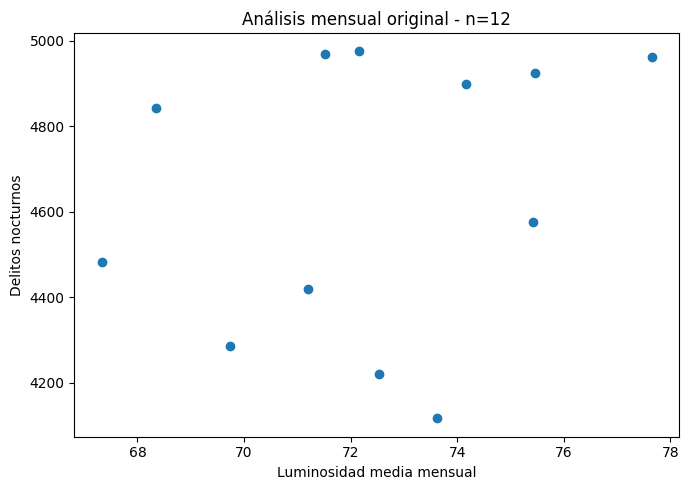

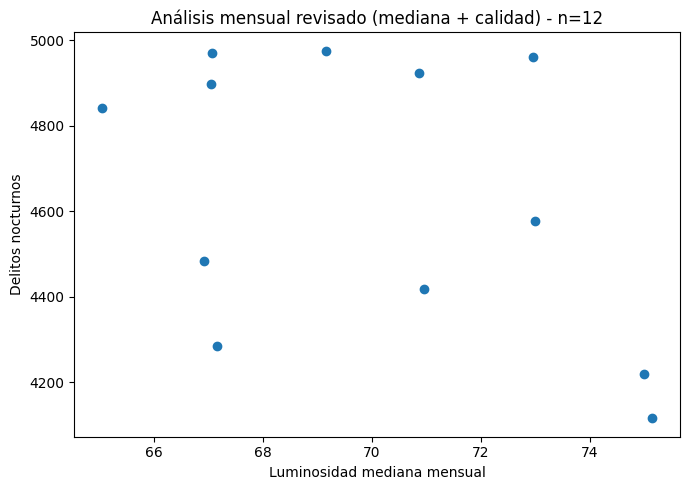

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(
    df_mensual["luminosidad_promedio_original"],
    df_mensual["delitos_nocturnos"]
)
plt.title("Análisis mensual original - n=12")
plt.xlabel("Luminosidad media mensual")
plt.ylabel("Delitos nocturnos")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(
    df_mensual["luminosidad_mediana_qc"],
    df_mensual["delitos_nocturnos"]
)
plt.title("Análisis mensual revisado (mediana + calidad) - n=12")
plt.xlabel("Luminosidad mediana mensual")
plt.ylabel("Delitos nocturnos")
plt.tight_layout()
plt.show()

## 7. Grilla territorial completa

La primera versión generaba celdas únicamente a partir de delitos observados.  
Eso excluía automáticamente las celdas con cero delitos nocturnos.

En esta versión se genera primero una grilla completa del **rectángulo de estudio** y luego se agregan los delitos.

> Limitación: sin incorporar una fuente externa de límites administrativos, la grilla representa el rectángulo de estudio y puede incluir sectores que no correspondan exactamente al territorio administrativo de CABA.

In [ ]:
TAM_LAT = 0.0045
TAM_LON = 0.0055

lat_edges = np.arange(LAT_MIN, LAT_MAX + TAM_LAT, TAM_LAT)
lon_edges = np.arange(LON_MIN, LON_MAX + TAM_LON, TAM_LON)

celdas = []
for i in range(len(lat_edges) - 1):
    for j in range(len(lon_edges) - 1):
        lat0, lat1 = lat_edges[i], min(lat_edges[i+1], LAT_MAX)
        lon0, lon1 = lon_edges[j], min(lon_edges[j+1], LON_MAX)
        if lat0 >= LAT_MAX or lon0 >= LON_MAX:
            continue

        zona_id = f"{lat0:.4f}_{lon0:.4f}"
        celdas.append({
            "zona_id": zona_id,
            "lat_min": lat0,
            "lat_max": lat1,
            "lon_min": lon0,
            "lon_max": lon1,
            "centro_lat": (lat0 + lat1) / 2,
            "centro_lon": (lon0 + lon1) / 2,
        })

df_grid = pd.DataFrame(celdas)

# Asignación de cada delito a una celda compatible con los mismos bordes
df_nocturno["grid_i"] = np.floor((df_nocturno["latitud"] - LAT_MIN) / TAM_LAT).astype(int)
df_nocturno["grid_j"] = np.floor((df_nocturno["longitud"] - LON_MIN) / TAM_LON).astype(int)

df_nocturno["grid_i"] = df_nocturno["grid_i"].clip(0, len(lat_edges)-2)
df_nocturno["grid_j"] = df_nocturno["grid_j"].clip(0, len(lon_edges)-2)

df_nocturno["lat_min"] = LAT_MIN + df_nocturno["grid_i"] * TAM_LAT
df_nocturno["lon_min"] = LON_MIN + df_nocturno["grid_j"] * TAM_LON
df_nocturno["zona_id"] = (
    df_nocturno["lat_min"].round(4).map(lambda x: f"{x:.4f}")
    + "_"
    + df_nocturno["lon_min"].round(4).map(lambda x: f"{x:.4f}")
)

delitos_por_zona = (
    df_nocturno.groupby("zona_id")
    .size()
    .reset_index(name="delitos_nocturnos")
)

df_grid = df_grid.merge(delitos_por_zona, on="zona_id", how="left")
df_grid["delitos_nocturnos"] = df_grid["delitos_nocturnos"].fillna(0).astype(int)

print("Celdas totales:", len(df_grid))
print("Celdas con >=1 delito nocturno:", (df_grid["delitos_nocturnos"] > 0).sum())
print("Celdas con 0 delitos nocturnos:", (df_grid["delitos_nocturnos"] == 0).sum())

display(df_grid["delitos_nocturnos"].describe())

Celdas totales: 1440
Celdas con >=1 delito nocturno: 817
Celdas con 0 delitos nocturnos: 623


,delitos_nocturnos
count,"1,440.0000"
mean,38.6611
std,58.5767
min,0.0000
25%,0.0000
50%,15.0000
75%,57.0000
max,472.0000


## 8. Integración espacial con NASA

A diferencia de la primera versión, que consultaba únicamente el punto central de cada celda, aquí cada zona se representa como un **polígono** y se calcula la radiancia dentro de la celda.

Se extraen:
- luminosidad media anual con control de calidad;
- luminosidad mediana anual con control de calidad.

La mediana se usa como medida principal de robustez; la media queda disponible para comparación.

In [ ]:
features = []

for row in df_grid.itertuples():
    geom = ee.Geometry.Rectangle([
        float(row.lon_min),
        float(row.lat_min),
        float(row.lon_max),
        float(row.lat_max)
    ])
    features.append(
        ee.Feature(geom, {
            "zona_id": row.zona_id,
            "delitos_nocturnos": int(row.delitos_nocturnos)
        })
    )

zonas_ee = ee.FeatureCollection(features)

luz_anual_media_qc = luminosidad_qc.mean().rename("luminosidad_media_qc")
luz_anual_mediana_qc = luminosidad_qc.median().rename("luminosidad_mediana_qc")

imagen_integrada = luz_anual_media_qc.addBands(luz_anual_mediana_qc)

zonas_luz = imagen_integrada.reduceRegions(
    collection=zonas_ee,
    reducer=ee.Reducer.mean(),
    scale=500
)

datos_zonas = zonas_luz.getInfo()["features"]
df_luz_zonas = pd.DataFrame([f["properties"] for f in datos_zonas])

df_zonas = df_grid.merge(
    df_luz_zonas.drop(columns=["delitos_nocturnos"], errors="ignore"),
    on="zona_id",
    how="left"
)

print("Dimensiones:", df_zonas.shape)
print("Nulos en luminosidad:")
print(df_zonas[["luminosidad_media_qc", "luminosidad_mediana_qc"]].isna().sum())

display(df_zonas.head())

Dimensiones: (1440, 10)
Nulos en luminosidad:
luminosidad_media_qc      0
luminosidad_mediana_qc    0
dtype: int64


,zona_id,lat_min,lat_max,lon_min,lon_max,centro_lat,centro_lon,delitos_nocturnos,luminosidad_media_qc,luminosidad_mediana_qc
0,-34.7050_-58.5315,-34.7050,-34.7005,-58.5315,-58.5260,-34.7027,-58.5288,0,57.6730,58.4768
1,-34.7050_-58.5260,-34.7050,-34.7005,-58.5260,-58.5205,-34.7027,-58.5233,0,77.8504,80.2540
2,-34.7050_-58.5205,-34.7050,-34.7005,-58.5205,-58.5150,-34.7027,-58.5178,0,88.5168,88.8527
3,-34.7050_-58.5150,-34.7050,-34.7005,-58.5150,-58.5095,-34.7027,-58.5123,0,90.6603,91.1545
4,-34.7050_-58.5095,-34.7050,-34.7005,-58.5095,-58.5040,-34.7027,-58.5068,0,89.4241,87.6243


## 9. Distribuciones y valores atípicos

Los outliers no se eliminan automáticamente.  
Se identifican con IQR y se realiza un análisis de sensibilidad para observar cuánto modifican las correlaciones.

,delitos_nocturnos,luminosidad_mediana_qc
count,"1,440.0000","1,440.0000"
mean,38.6611,70.6417
std,58.5767,35.9365
min,0.0000,1.9429
25%,0.0000,57.7886
50%,15.0000,70.8116
75%,57.0000,91.8050
max,472.0000,294.2242



delitos_nocturnos
Q1: 0.0 | Q3: 57.0 | IQR: 57.0
Límite inferior: -85.5 | Límite superior: 142.5
Observaciones fuera de IQR: 76


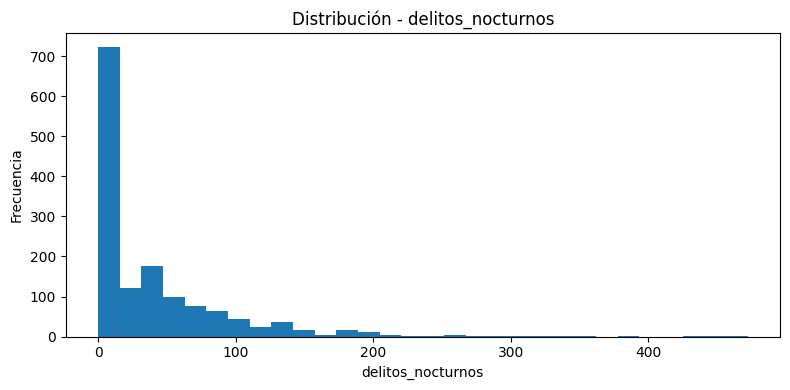

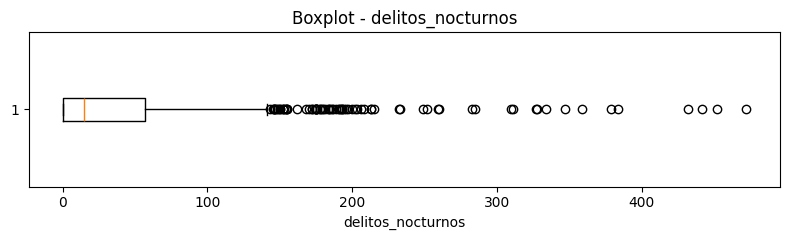


luminosidad_mediana_qc
Q1: 57.78858864594146 | Q3: 91.80502155509035 | IQR: 34.01643290914889
Límite inferior: 6.763939282218125 | Límite superior: 142.8296709188137
Observaciones fuera de IQR: 192


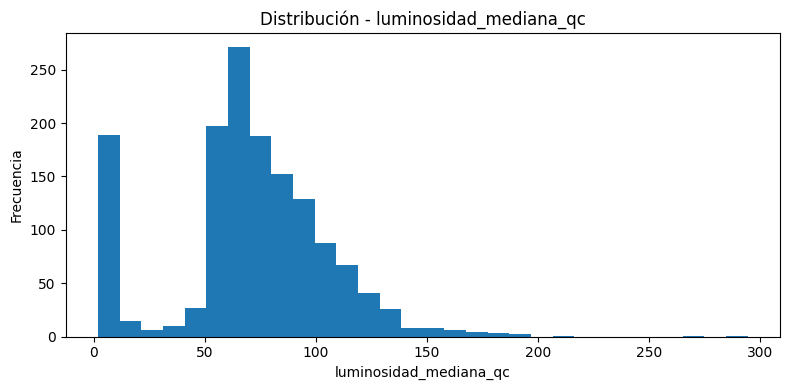

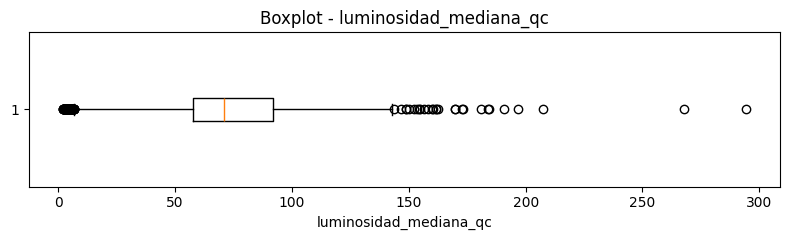

In [ ]:
variables = ["delitos_nocturnos", "luminosidad_mediana_qc"]

display(df_zonas[variables].describe())

for col in variables:
    serie = df_zonas[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr

    print(f"\n{col}")
    print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
    print("Límite inferior:", li, "| Límite superior:", ls)
    print("Observaciones fuera de IQR:", ((serie < li) | (serie > ls)).sum())

    plt.figure(figsize=(8, 4))
    plt.hist(serie, bins=30)
    plt.title(f"Distribución - {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 2.5))
    plt.boxplot(serie, vert=False)
    plt.title(f"Boxplot - {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

## 10. Correlaciones espaciales y análisis de sensibilidad

N espacial: 1440
Pearson espacial: 0.105
Spearman espacial: -0.026

Sensibilidad sin extremos IQR (NO es el dataset principal):
N: 1173
Pearson: -0.183
Spearman: -0.333


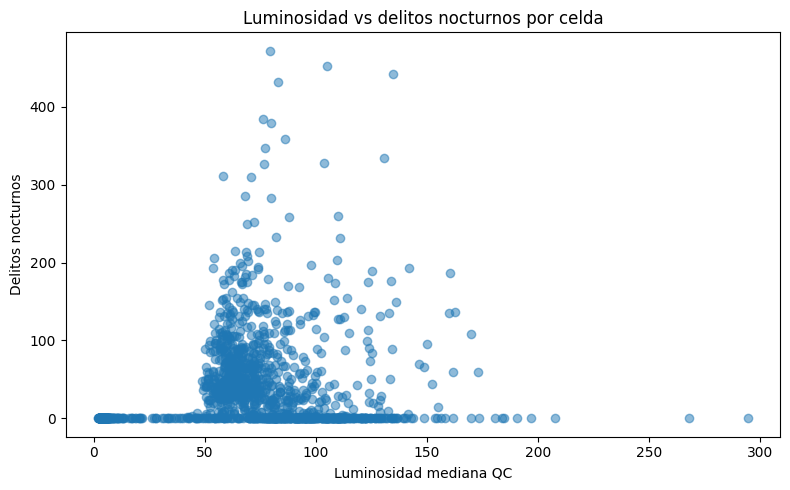

In [ ]:
df_corr = df_zonas[
    ["delitos_nocturnos", "luminosidad_mediana_qc"]
].dropna().copy()

pearson_espacial = df_corr.corr(method="pearson").iloc[0, 1]
spearman_espacial = df_corr.corr(method="spearman").iloc[0, 1]

# Sensibilidad: sin extremos IQR de ambas variables.
mask = pd.Series(True, index=df_corr.index)

for col in df_corr.columns:
    q1, q3 = df_corr[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask &= df_corr[col].between(li, ls)

df_corr_sin_extremos = df_corr.loc[mask]

pearson_sin_extremos = df_corr_sin_extremos.corr(method="pearson").iloc[0, 1]
spearman_sin_extremos = df_corr_sin_extremos.corr(method="spearman").iloc[0, 1]

print("N espacial:", len(df_corr))
print("Pearson espacial:", round(pearson_espacial, 3))
print("Spearman espacial:", round(spearman_espacial, 3))

print("\nSensibilidad sin extremos IQR (NO es el dataset principal):")
print("N:", len(df_corr_sin_extremos))
print("Pearson:", round(pearson_sin_extremos, 3))
print("Spearman:", round(spearman_sin_extremos, 3))

plt.figure(figsize=(8, 5))
plt.scatter(
    df_corr["luminosidad_mediana_qc"],
    df_corr["delitos_nocturnos"],
    alpha=0.5
)
plt.title("Luminosidad vs delitos nocturnos por celda")
plt.xlabel("Luminosidad mediana QC")
plt.ylabel("Delitos nocturnos")
plt.tight_layout()
plt.show()

## 11. Dependencia no lineal

Se calcula **información mutua** como medida exploratoria de dependencia no lineal.

También se compara, mediante validación cruzada, una relación lineal simple contra una transformación polinómica de grado 2.  
Esto no busca “forzar” un resultado alto: sirve para comprobar si una forma no lineal simple describe mejor los datos.

In [ ]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

X_nl = df_corr[["luminosidad_mediana_qc"]]
y_nl = df_corr["delitos_nocturnos"]

mi = mutual_info_regression(
    X_nl,
    y_nl,
    random_state=42
)[0]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

modelo_lineal = LinearRegression()
modelo_polinomico = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

r2_lineal = cross_val_score(
    modelo_lineal, X_nl, y_nl, cv=cv, scoring="r2"
)

r2_poly = cross_val_score(
    modelo_polinomico, X_nl, y_nl, cv=cv, scoring="r2"
)

print("Información mutua:", round(mi, 4))
print("R² CV lineal:", round(r2_lineal.mean(), 4))
print("R² CV polinómico grado 2:", round(r2_poly.mean(), 4))
print("\nNota: MI no tiene la misma escala interpretativa que Pearson.")

Información mutua: 0.3228
R² CV lineal: 0.0095
R² CV polinómico grado 2: 0.0538

Nota: MI no tiene la misma escala interpretativa que Pearson.


## 12. Clasificación relativa Bajo / Medio / Alto

Las categorías se construyen por terciles de la distribución observada.

- Son **categorías relativas del dataset**.
- No equivalen a “seguro”, “inseguro” ni a una clasificación oficial de peligrosidad.
- Se muestran los límites resultantes para que el criterio sea transparente.

In [ ]:
# ============================================================
# 12. CLASIFICACIÓN RELATIVA DE INCIDENCIA
# ============================================================

# Inicialmente distinguimos las celdas sin registros nocturnos.
df_zonas["nivel_incidencia"] = "Sin registros nocturnos"

# Trabajamos los terciles solamente sobre zonas con al menos
# un delito nocturno registrado.
mask_con_delitos = df_zonas["delitos_nocturnos"] > 0

delitos_positivos = df_zonas.loc[
    mask_con_delitos,
    "delitos_nocturnos"
]

# Límites de los terciles sobre zonas con registros.
q33 = delitos_positivos.quantile(1/3)
q67 = delitos_positivos.quantile(2/3)

# Clasificación relativa.
df_zonas.loc[
    mask_con_delitos & (df_zonas["delitos_nocturnos"] <= q33),
    "nivel_incidencia"
] = "Bajo"

df_zonas.loc[
    mask_con_delitos
    & (df_zonas["delitos_nocturnos"] > q33)
    & (df_zonas["delitos_nocturnos"] <= q67),
    "nivel_incidencia"
] = "Medio"

df_zonas.loc[
    mask_con_delitos & (df_zonas["delitos_nocturnos"] > q67),
    "nivel_incidencia"
] = "Alto"

# Orden lógico de las categorías.
orden_categorias = [
    "Sin registros nocturnos",
    "Bajo",
    "Medio",
    "Alto"
]

df_zonas["nivel_incidencia"] = pd.Categorical(
    df_zonas["nivel_incidencia"],
    categories=orden_categorias,
    ordered=True
)

print("=== CLASIFICACIÓN RELATIVA DE INCIDENCIA ===")

print("\nUmbral Bajo / Medio:")
print(round(q33, 2))

print("\nUmbral Medio / Alto:")
print(round(q67, 2))

print("\nDistribución de zonas:")
print(
    df_zonas["nivel_incidencia"]
    .value_counts()
    .reindex(orden_categorias)
)

print("\nIMPORTANTE:")
print(
    "Bajo, Medio y Alto son categorías relativas a la distribución "
    "de zonas con delitos nocturnos registrados."
)
print(
    "'Sin registros nocturnos' significa que no se observaron delitos "
    "nocturnos en esa celda dentro del dataset analizado; "
    "no significa que la zona sea segura."
)

=== CLASIFICACIÓN RELATIVA DE INCIDENCIA ===

Umbral Bajo / Medio:
36.0

Umbral Medio / Alto:
71.0

Distribución de zonas:
nivel_incidencia
Sin registros nocturnos    623
Bajo                       277
Medio                      269
Alto                       271
Name: count, dtype: int64

IMPORTANTE:
Bajo, Medio y Alto son categorías relativas a la distribución de zonas con delitos nocturnos registrados.
'Sin registros nocturnos' significa que no se observaron delitos nocturnos en esa celda dentro del dataset analizado; no significa que la zona sea segura.


## 13. Perfiles territoriales con los datos existentes

Se construyen indicadores por celda sin agregar fuentes externas:
- delitos nocturnos;
- proporción de fines de semana;
- hora predominante;
- tipo de delito predominante;
- distribución porcentual de tipos principales;
- luminosidad mediana.

In [ ]:
base_perfiles = df_nocturno.groupby("zona_id").agg(
    delitos_nocturnos=("id-mapa", "size"),
    proporcion_fin_semana=("es_fin_de_semana", "mean"),
    hora_promedio=("franja", "mean")
).reset_index()

hora_moda = (
    df_nocturno.groupby("zona_id")["franja"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
    .rename("hora_predominante")
    .reset_index()
)

tipo_pred = (
    df_nocturno.groupby("zona_id")["tipo"]
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
    .rename("tipo_predominante")
    .reset_index()
)

tipos_pct = pd.crosstab(
    df_nocturno["zona_id"],
    df_nocturno["tipo"],
    normalize="index"
).mul(100)

tipos_pct.columns = [
    "pct_" + str(c).lower().replace(" ", "_")
    for c in tipos_pct.columns
]
tipos_pct = tipos_pct.reset_index()

df_perfiles = (
    df_zonas
    .merge(base_perfiles.drop(columns=["delitos_nocturnos"]), on="zona_id", how="left")
    .merge(hora_moda, on="zona_id", how="left")
    .merge(tipo_pred, on="zona_id", how="left")
    .merge(tipos_pct, on="zona_id", how="left")
)

df_perfiles["proporcion_fin_semana"] = df_perfiles["proporcion_fin_semana"].fillna(0)

pct_cols = [c for c in df_perfiles.columns if c.startswith("pct_")]
df_perfiles[pct_cols] = df_perfiles[pct_cols].fillna(0)

display(df_perfiles.head())

,zona_id,lat_min,lat_max,lon_min,lon_max,centro_lat,centro_lon,delitos_nocturnos,luminosidad_media_qc,luminosidad_mediana_qc,nivel_incidencia,proporcion_fin_semana,hora_promedio,hora_predominante,tipo_predominante,pct_amenazas,pct_homicidios,pct_hurto,pct_lesiones,pct_robo,pct_vialidad
0,-34.7050_-58.5315,-34.7050,-34.7005,-58.5315,-58.5260,-34.7027,-58.5288,0,57.6730,58.4768,Sin registros nocturnos,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,-34.7050_-58.5260,-34.7050,-34.7005,-58.5260,-58.5205,-34.7027,-58.5233,0,77.8504,80.2540,Sin registros nocturnos,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,-34.7050_-58.5205,-34.7050,-34.7005,-58.5205,-58.5150,-34.7027,-58.5178,0,88.5168,88.8527,Sin registros nocturnos,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,-34.7050_-58.5150,-34.7050,-34.7005,-58.5150,-58.5095,-34.7027,-58.5123,0,90.6603,91.1545,Sin registros nocturnos,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,-34.7050_-58.5095,-34.7050,-34.7005,-58.5095,-58.5040,-34.7027,-58.5068,0,89.4241,87.6243,Sin registros nocturnos,0.0000,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 14. Evaluación exploratoria de K-Means

K-Means se usa únicamente para explorar **perfiles territoriales**.

No se interpretan los clusters como:
- nivel de peligrosidad;
- predicción de delitos;
- clasificación oficial de seguridad.

Se evalúan varios valores de `k` mediante silhouette score.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

features_kmeans = [
    "delitos_nocturnos",
    "luminosidad_mediana_qc",
    "proporcion_fin_semana",
]

# Agregar porcentajes de tipos si están disponibles
features_kmeans += pct_cols

df_km = df_perfiles[["zona_id"] + features_kmeans].copy()
df_km = df_km.dropna()

print("Variables candidatas:")
print(features_kmeans)
print("Observaciones utilizables:", len(df_km))

if len(df_km) >= 20 and len(features_kmeans) >= 2:
    scaler = StandardScaler()
    X_km = scaler.fit_transform(df_km[features_kmeans])

    resultados_k = []
    for k in range(2, 7):
        km = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = km.fit_predict(X_km)
        score = silhouette_score(X_km, labels)
        resultados_k.append({"k": k, "silhouette": score})

    df_silhouette = pd.DataFrame(resultados_k)
    display(df_silhouette)

    mejor_k = int(df_silhouette.loc[df_silhouette["silhouette"].idxmax(), "k"])
    print("Mejor k exploratorio por silhouette:", mejor_k)

    km_final = KMeans(n_clusters=mejor_k, random_state=42, n_init=20)
    df_km["cluster"] = km_final.fit_predict(X_km)

    df_perfiles = df_perfiles.merge(
        df_km[["zona_id", "cluster"]],
        on="zona_id",
        how="left"
    )

    print("\nPerfil promedio por cluster:")
    display(
        df_perfiles.groupby("cluster")[features_kmeans]
        .mean()
        .round(2)
    )
else:
    print("No hay estructura suficiente para justificar K-Means con estas variables.")

Variables candidatas:
['delitos_nocturnos', 'luminosidad_mediana_qc', 'proporcion_fin_semana', 'pct_amenazas', 'pct_homicidios', 'pct_hurto', 'pct_lesiones', 'pct_robo', 'pct_vialidad']
Observaciones utilizables: 1440


,k,silhouette
0,2,0.4388
1,3,0.4549
2,4,0.4677
3,5,0.4981
4,6,0.4656


Mejor k exploratorio por silhouette: 5

Perfil promedio por cluster:


,delitos_nocturnos,luminosidad_mediana_qc,proporcion_fin_semana,pct_amenazas,pct_homicidios,pct_hurto,pct_lesiones,pct_robo,pct_vialidad
cluster,,,,,,,,,
0,0.0100,100.0900,0.0000,0.0000,0.0000,0.0000,0.0000,0.5100,0.0000
1,69.7100,73.8200,0.3200,4.1300,0.0300,37.0300,5.3500,48.7600,4.7000
2,71.2200,78.7500,0.3100,5.9000,3.2500,23.9400,6.6000,55.4200,4.8900
3,0.0000,10.1200,0.0000,0.0000,0.0000,0.0000,0.0000,0.4300,0.0000
4,5.5900,78.5100,0.4000,1.9600,0.0000,3.8000,3.7800,16.4500,74.0100


## 15. Tablas útiles para el dashboard

In [ ]:
tabla_indicadores = pd.DataFrame({
    "indicador": [
        "registros_originales",
        "registros_base_validos",
        "delitos_nocturnos",
        "celdas_totales",
        "celdas_con_delitos_nocturnos",
        "celdas_sin_delitos_nocturnos",
        "pearson_mensual_original",
        "pearson_espacial_revisado",
        "spearman_espacial_revisado"
    ],
    "valor": [
        len(df_raw),
        len(df_base),
        len(df_nocturno),
        len(df_zonas),
        int((df_zonas["delitos_nocturnos"] > 0).sum()),
        int((df_zonas["delitos_nocturnos"] == 0).sum()),
        pearson_mensual_original,
        pearson_espacial,
        spearman_espacial
    ]
})

tabla_comuna = (
    df_base.groupby("comuna")
    .size()
    .reset_index(name="delitos_total")
    .sort_values("delitos_total", ascending=False)
)

tabla_barrio = (
    df_base.groupby("barrio")
    .size()
    .reset_index(name="delitos_total")
    .sort_values("delitos_total", ascending=False)
)

tabla_mes = (
    df_base.groupby("mes_num")
    .size()
    .reset_index(name="delitos_total")
)

tabla_hora = (
    df_base.groupby("franja")
    .size()
    .reset_index(name="delitos_total")
)

tabla_tipo = (
    df_base.groupby("tipo")
    .size()
    .reset_index(name="delitos_total")
    .sort_values("delitos_total", ascending=False)
)

display(tabla_indicadores)

,indicador,valor
0,registros_originales,"158,838.0000"
1,registros_base_validos,"154,875.0000"
2,delitos_nocturnos,"55,672.0000"
3,celdas_totales,"1,440.0000"
4,celdas_con_delitos_nocturnos,817.0000
5,celdas_sin_delitos_nocturnos,623.0000
6,pearson_mensual_original,0.2695
7,pearson_espacial_revisado,0.1045
8,spearman_espacial_revisado,-0.0263


## 16. Disponibilidad de indicadores

### Disponibles actualmente
- conteos por tipo, comuna, barrio, mes, día y franja;
- delitos nocturnos;
- luminosidad mensual y territorial;
- correlaciones mensual y espacial;
- distribuciones y outliers;
- categorías relativas Bajo / Medio / Alto;
- perfiles territoriales por celda;
- clusters exploratorios, si resultan viables.

### Requieren reprocesamiento
- cualquier cambio de definición del período nocturno;
- distintos tamaños de grilla;
- nuevas reglas de calidad satelital.

### No pueden calcularse sólidamente con los datos actuales
- tasa de delitos por población;
- exposición por circulación de personas;
- peligrosidad absoluta;
- causalidad entre iluminación y delito;
- efectividad policial;
- predicción confiable de ocurrencia de un delito sin una definición/modelado adicional.

## 17. Limitaciones metodológicas

1. Los registros de delitos representan hechos registrados y no necesariamente todos los hechos ocurridos.
2. Los conteos territoriales no están normalizados por población, tránsito peatonal o exposición.
3. El área geográfica usada es un rectángulo aproximado y no el polígono administrativo exacto de CABA.
4. La radiancia VIIRS representa luz nocturna detectada por satélite; no equivale exclusivamente a alumbrado público.
5. El análisis mensual tiene solo 12 observaciones y debe interpretarse como exploratorio.
6. Correlación y dependencia estadística no implican causalidad.
7. La clasificación Bajo / Medio / Alto es relativa a la distribución observada.
8. Los clusters de K-Means, si se utilizan, representan perfiles estadísticos y no niveles de peligrosidad.

## 18. Exportación reproducible de resultados

In [ ]:
from pathlib import Path
import shutil

OUT = Path("/content/data_horizon_outputs")
OUT.mkdir(exist_ok=True)

df_base.to_csv(OUT / "delitos_2024_limpio.csv", index=False)
df_nocturno.to_csv(OUT / "delitos_2024_nocturnos.csv", index=False)
df_mensual.to_csv(OUT / "analisis_mensual_luz_delitos.csv", index=False)
df_zonas.to_csv(OUT / "dataset_inteligencia_territorial_v2.csv", index=False)
df_perfiles.to_csv(OUT / "perfiles_territoriales.csv", index=False)

tabla_indicadores.to_csv(OUT / "dashboard_indicadores.csv", index=False)
tabla_comuna.to_csv(OUT / "dashboard_comunas.csv", index=False)
tabla_barrio.to_csv(OUT / "dashboard_barrios.csv", index=False)
tabla_mes.to_csv(OUT / "dashboard_meses.csv", index=False)
tabla_hora.to_csv(OUT / "dashboard_horas.csv", index=False)
tabla_tipo.to_csv(OUT / "dashboard_tipos.csv", index=False)

zip_path = shutil.make_archive(
    "/content/data_horizon_outputs",
    "zip",
    OUT
)

print("Archivos generados en:", OUT)
print("ZIP:", zip_path)
print("\nContenido:")
for p in sorted(OUT.iterdir()):
    print("-", p.name)

Archivos generados en: /content/data_horizon_outputs
ZIP: /content/data_horizon_outputs.zip

Contenido:
- analisis_mensual_luz_delitos.csv
- dashboard_barrios.csv
- dashboard_comunas.csv
- dashboard_horas.csv
- dashboard_indicadores.csv
- dashboard_meses.csv
- dashboard_tipos.csv
- dataset_inteligencia_territorial_v2.csv
- delitos_2024_limpio.csv
- delitos_2024_nocturnos.csv
- perfiles_territoriales.csv
